In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install tabulate

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
from ucimlrepo import fetch_ucirepo # Importação de Dados
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from pathlib import Path

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

root = os.getcwd()
EDA_DIR = root / "artifacts" / "presentation" / "eda"

def save_fig(fig, name, dpi=150):
    """Persiste na figura do repositório do EDA"""
    path = EDA_DIR / f"{name}.png"
    fig.save_file(path, dpi=dpi, bbox_inches="tight")
    print("saved")

# 1) Carga de Dados

In [4]:
# Busca do Dataset
rt_iot2022 = fetch_ucirepo(id=942)

# Seperação das features com a coluna Target
x = rt_iot2022.data.features
y = rt_iot2022.data.targets

# União das Linhas e Colunas
df_iot2022 = pd.concat([x, y], axis=1)

# Definição da coluna target
target_column = y.columns[0]

print(f'Shape: {df_iot2022.shape}')
print(f'Target: {target_column}\n')

Shape: (123117, 84)
Target: Attack_type



In [5]:
df_iot2022.head(15)

,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,761.985779,2.972918e+07,3.201160e+07,4001449.734,10403073.63,4438.877106,1511693.954,2.026391e+06,506597.757339,680406.147100,761.985779,2.972918e+07,3.201160e+07,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.282415e+06,2.282415e+06,2.282415e+06,2.282415e+06,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,247.001648,2.985528e+07,3.188358e+07,3985448.003,10463455.56,4214.048386,1576435.804,1.876261e+06,469065.249000,741351.686200,247.001648,2.985528e+07,3.188358e+07,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.028307e+06,2.028307e+06,2.028307e+06,2.028307e+06,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,74,8.222222,12.852799,0,21,30,6.0,8.689074,0,33,104,7.428571,11.229866,283.956528,2.984215e+07,3.212405e+07,4015506.625,10442377.92,2456.903458,1476048.946,2.013770e+06,503442.466300,660344.360027,283.956528,2.984215e+07,3.212405e+07,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.281904e+06,2.281904e+06,2.281904e+06,2.281904e+06,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,74,8.222222,12.852799,0,21,30,6.0,8.689074,0,33,104,7.428571,11.229866,288.963318,2.991377e+07,3.196106e+07,3995132.893,10482528.22,3933.906555,1551892.042,1.883784e+06,470946.013927,724569.317900,288.963318,2.991377e+07,3.196106e+07,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.047288e+06,2.047288e+06,2.047288e+06,2.047288e+06,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,387.907028,2.981470e+07,3.190236e+07,3987795.234,10447019.10,3005.027771,1632083.178,1.9359

In [20]:
definition_dict = {
    "Identificador de Conexão": [
        ("id.orig_p", "Porta de origem do dispositivo que inicia a comunicação"),
        ("id.resp_p", "Porta de destino do dispositivo que responde"),
        ("proto",     "Protocolo de transporte utilizado (ex: TCP, UDP, ICMP)"),
        ("service",   "Serviço de camada de aplicação detectado (ex: HTTP, DNS, SSH)")
    ],

    "Métricas de Fluxo (contagem e taxa)": [
        ("flow_duration",     "Duração total do fluxo bidirecional (em milissegundos)"),
        ("fwd_pkts_tot",      "Total de pacotes enviados no sentido de ida (origem → destino)"),
        ("bwd_pkts_tot",      "Total de pacotes enviados no sentido de volta (destino → origem)"),
        ("fwd_data_pkts_tot", "Total de pacotes de dados (com payload) no sentido de ida"),
        ("bwd_data_pkts_tot", "Total de pacotes de dados (com payload) no sentido de volta"),
        ("fwd_pkts_per_sec",  "Taxa de pacotes de ida por segundo"),
        ("bwd_pkts_per_sec",  "Taxa de pacotes de volta por segundo"),
        ("flow_pkts_per_sec", "Taxa combinada de todos os pacotes do fluxo por segundo"),
        ("down_up_ratio",     "Proporção entre o volume de dados de volta (download) e de ida (upload)"),
    ],

    "Cabeçalhos (Header Size)": [
        ("fwd_header_size_tot", "Tamanho total dos cabeçalhos dos pacotes de ida"),
        ("fwd_header_size_min", "Menor tamanho de cabeçalho entre os pacotes de ida"),
        ("fwd_header_size_max", "Maior tamanho de cabeçalho entre os pacotes de ida"),
        ("bwd_header_size_tot", "Tamanho total dos cabeçalhos dos pacotes de volta"),
        ("bwd_header_size_min", "Menor tamanho de cabeçalho entre os pacotes de volta"),
        ("bwd_header_size_max", "Maior tamanho de cabeçalho entre os pacotes de volta"),
    ],

    "Contagem de Flags TCP": [
        ("flow_FIN_flag_count", "Número de flags FIN (usadas para encerrar conexões)"),
        ("flow_SYN_flag_count", "Número de flags SYN (usadas para iniciar conexões)"),
        ("flow_RST_flag_count", "Número de flags RST (usadas para resetar conexões)"),
        ("fwd_PSH_flag_count",  "Número de flags PSH em pacotes de ida (envio imediato de dados)"),
        ("bwd_PSH_flag_count",  "Número de flags PSH em pacotes de volta"),
        ("flow_ACK_flag_count", "Número de flags ACK (confirmam recebimento)"),
        ("fwd_URG_flag_count",  "Número de flags URG em pacotes de ida (dados urgentes)"),
        ("bwd_URG_flag_count",  "Número de flags URG em pacotes de volta"),
        ("flow_CWR_flag_count", "Número de flags CWR (controle de congestionamento)"),
        ("flow_ECE_flag_count", "Número de flags ECE (Notificação Explícita de Congestionamento)"),
    ],

    "Métricas de Payload (carga útil)": [
        (f"{d}_pkts_payload.{s}", desc) for d in ("fwd", "bwd", "flow")
        for s, desc in [
            ("min", f"Tamanho mínimo do payload ({d})."),
            ("max", f"Tamanho máximo do payload ({d})."),
            ("tot", f"Tamanho total do payload ({d})."),
            ("avg", f"Tamanho médio do payload ({d})."),
            ("std", f"Desvio padrão do tamanho do payload ({d})."),
        ]
    ],

    "Tempo entre Chegadas (IAT - Interval Arrival Time)": [
        (f"{d}_iat.{s}", desc) for d in ("fwd", "bwd", "flow")
        for s, desc in [
            ("min", f"Tempo mínimo entre as chegadas consecutivas ({d})"),
            ("max", f"Tempo máximo entre as chegadas consecutivas ({d})"),
            ("tot", f"Tempo mínimo entre as chegadas ({d})"),
            ("avg", f"Tempo médio entre chegadas ({d})"),
            ("std",  f"Desvio padrão do tempo entre chegadas ({d})"),
        ]
    ],

    "Subfluxos, Bulk e Throughput": [
        ("payload_bytes_per_second", "Taxa de bytes de payload transferidos por segundo"),
        ("fwd_subflow_pkts",  "Número de pacotes em subfluxos de ida"),
        ("bwd_subflow_pkts",  "Número de pacotes em subfluxos de volta"),
        ("fwd_subflow_bytes", "Total de bytes em subfluxos de ida"),
        ("bwd_subflow_bytes", "Total de bytes em subfluxos de volta"),
        ("fwd_bulk_bytes",    "Bytes transferidos em modo bulk (rajada) no sentido de ida"),
        ("bwd_bulk_bytes",    "Bytes transferidos em modo bulk no sentido de volta"),
        ("fwd_bulk_packets",  "Número de pacotes em modo bulk no sentido de ida"),
        ("bwd_bulk_packets",  "Número de pacotes em modo bulk no sentido de volta"),
        ("fwd_bulk_rate",     "Taxa de transferência bulk no sentido de ida"),
        ("bwd_bulk_rate",     "Taxa de transferência bulk no sentido de volta"),
    ],

    "Tempos Ativo e Inativo": [
            (f"active.{s}", desc) for s, desc in [
                ("min", "Tempo mínimo de atividade no fluxo"),
                ("max", "Tempo máximo de atividade no fluxo"),
                ("tot", "Tempo total de atividade no fluxo"),
                ("avg", "Tempo médio de atividade no fluxo"),
                ("std", "Desvio padrão dos tempos de atividade no fluxo"),
            ]
        ] + [
            (f"idle.{s}", desc) for s, desc in [
                ("min", "Tempo mínimo de inatividade no fluxo"),
                ("max", "Tempo máximo de inatividade no fluxo"),
                ("tot", "Tempo total de inatividade no fluxo"),
                ("avg", "Tempo médio de inatividade no fluxo"),
                ("std", "Desvio padrão dos tempos de inatividade no fluxo"),
            ]
        ],
    
    "Tamanho de Janela (TCP Window)": [
        ("fwd_init_window_size", "Tamanho inicial da janela TCP no sentido de ida"),
        ("bwd_init_window_size", "Tamanho inicial da janela TCP no sentido de volta"),
        ("fwd_last_window_size", "Último tamanho de janela observado no sentido de ida"),
    ],

    "Coluna Target": [
        ("Attack_type", "Rótulo que classifica o registro como tráfego normal ou um tipo específico de ataque")
    ]
}

desc_df = pd.DataFrame(
    [
        (cat, col, desc) 
        for cat, itens in definition_dict.items()
        for col, desc in itens
    ], columns=["Categoria", "Coluna", "Descrição"],
)

desc_df["dtype"] = desc_df["Coluna"].map(df_iot2022.dtypes).astype(str)
desc_df["nunique"] = desc_df["Coluna"].map(df_iot2022.nunique())
desc_df["%_nulls"] = (desc_df["Coluna"].map(df_iot2022.isnull().mean()) * 100).round(2)


print(desc_df.to_markdown(index=True))

|    | Categoria                                          | Coluna                   | Descrição                                                                            | dtype   |   nunique |   %_nulls |
|---:|:---------------------------------------------------|:-------------------------|:-------------------------------------------------------------------------------------|:--------|----------:|----------:|
|  0 | Identificador de Conexão                           | id.orig_p                | Porta de origem do dispositivo que inicia a comunicação                              | int64   |     65478 |         0 |
|  1 | Identificador de Conexão                           | id.resp_p                | Porta de destino do dispositivo que responde                                         | int64   |      1809 |         0 |
|  2 | Identificador de Conexão                           | proto                    | Protocolo de transporte utilizado (ex: TCP, UDP, ICMP)                           

# 2) Análise de Dados

### 2.1) Report Básico

In [21]:
df = df_iot2022.copy()
numeric_columns = df.select_dtypes(include=np.number).columns.to_list()
feature_columns = [c for c in df.columns if c != target_column]

#### 2.1.1) Avaliação de Duplicadas

In [22]:
all_duplicated = df.duplicated(subset=feature_columns + [target_column]).sum()
feature_duplicated = df.duplicated(subset=feature_columns).sum()
n_conflicts = (df.groupby(feature_columns)[target_column].nunique() > 1).sum()

duplicated_per_class = df.groupby(target_column).apply(lambda x: x.duplicated(subset=feature_columns).sum()).sort_values(ascending=True)

# Avaliação de conflitos de linhas
conflict_groups = df.groupby(feature_columns)[target_column].nunique()
rows_in_conflict = conflict_groups[conflict_groups > 1].index
mask_conflict = df.set_index(feature_columns).index.isin(rows_in_conflict)

print(f'Duplicadas Completas: {all_duplicated}')
print(f'Duplicadas com apenas as features: {feature_duplicated}')
print(f'Grupos com rótulos conflitantes: {n_conflicts}')
print(f'Linhas em grupos conflitantes: {mask_conflict.sum()}')

display(duplicated_per_class)

C:\Users\rpf97\AppData\Local\Temp\ipykernel_10316\3547881387.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  duplicated_per_class = df.groupby(target_column).apply(lambda x: x.duplicated(subset=feature_columns).sum()).sort_values(ascending=True)


Duplicadas Completas: 5195
Duplicadas com apenas as features: 5202
Grupos com rótulos conflitantes: 6
Linhas em grupos conflitantes: 128


Attack_type
NMAP_OS_DETECTION                0
NMAP_TCP_scan                    0
NMAP_FIN_SCAN                    0
NMAP_XMAS_TREE_SCAN              0
Metasploit_Brute_Force_SSH       1
DDOS_Slowloris                   1
MQTT_Publish                     4
NMAP_UDP_SCAN                    6
Wipro_bulb                      34
ARP_poisioning                 125
Thing_Speak                    454
DOS_SYN_Hping                 4570
dtype: int64

#### 2.1.2) Report Básico

In [ ]:
# Avaliação de Calores numéricos
report = {}

# Quantidade de Valores Nulos
report['nulos'] = int(df.isnull().sum().sum())

# Quantidade de Colunas numéricas
report['colunas_numericas'] = len(numeric_columns)

# Valores Infinitos
report['valores_infinitos'] = np.isinf(df[numeric_columns]).sum().sum()

# Valores Negativos
report['negativos'] = int((df[numeric_columns] < 0).sum().sum())

# Avaliação de Duplicadas
#report['duplicadas_antes'] = int(df.duplicated().sum())
#df = df.drop_duplicates().reset_index(drop=True)

# Remoção das colunas constantes
constant_columns = [c for c in df.columns if df[c].nunique() <= 1]
report['constantes_removidas'] = constant_columns

df = df.drop(columns=constant_columns, axis=1)

# Shape Principal
report['shape_principal'] = df.shape

# Atualização das Colunas Numéricas:
numeric_columns = df.select_dtypes(include=np.number).columns.to_list()
print(pd.Series(report).to_markdown(index=True))

|                      | 0                      |
|:---------------------|:-----------------------|
| nulos                | 0                      |
| colunas_numericas    | 81                     |
| valores_infinitos    | 0                      |
| negativos            | 0                      |
| constantes_removidas | ['bwd_URG_flag_count'] |
| shape_principal      | (123117, 83)           |


#### 2.1.3) Descrição de Dados

In [24]:
describe_df = df.describe().T

describe_df['nunique'] = df[numeric_columns].nunique()
describe_df['skew'] = df[numeric_columns].skew() # mede o lado de onde a direção segue (=0 (normal), > 0 (cauda longa a direita), < 0 (cauda longa a esquerda))
describe_df['kurtosis'] = df[numeric_columns].kurtosis() # mede o peso das caudas (=~3 (cauda 'normal'), > 3 (cauda pesada), < 3 (cauda leve, de distribuição limitada))

display(describe_df)

,count,mean,std,min,25%,50%,75%,max,nunique,skew,kurtosis
id.orig_p,123117.0,3.463926e+04,1.907062e+04,0.0,17702.000000,3.722100e+04,5.097100e+04,6.553500e+04,65478,-0.234187,-1.190356
id.resp_p,123117.0,1.014305e+03,5.256372e+03,0.0,21.000000,2.100000e+01,2.100000e+01,6.538900e+04,1809,7.984647,70.583266
flow_duration,123117.0,3.809566e+00,1.300054e+02,0.0,0.000001,4.000000e-06,5.000000e-06,2.172834e+04,16381,120.962461,16604.647931
fwd_pkts_tot,123117.0,2.268826e+00,2.233656e+01,0.0,1.000000,1.000000e+00,1.000000e+00,4.345000e+03,163,121.437397,18970.642593
bwd_pkts_tot,123117.0,1.909509e+00,3.301831e+01,0.0,1.000000,1.000000e+00,1.000000e+00,1.011200e+04,172,249.909345,73012.043010
fwd_data_pkts_tot,123117.0,1.471218e+00,1.963520e+01,0.0,1.000000,1.000000e+00,1.000000e+00,4.345000e+03,116,158.497008,29937.376832
bwd_data_pkts_tot,123117.0,8.202604e-01,3.229395e+01,0.0,0.000000,0.000000e+00,0.000000e+00,1.010500e+04,154,264.030712,79376.087690
fwd_pkts_per_sec,123117.0,3.518063e+05,3.707645e+05,0.0,74.543538,2.467238e+05,5.242880e+05,1.048576e+06,15891,0.994444,-0.469203
bwd_pkts_per_sec,123117.0,3.517620e+05,3.708015e+05,0.0,72.889275,2.467238e+05,5.242880e+05,1.048576e+06,15428,0.994235,-0.469410
flow_pkts_per_sec,123117.0,7.035683e+05,7.415634e+05,0.0,149.087077,4.934475e+05,1.048576e+06,2.097152e+06,16111,0.994360,-0.469286


### 2.2) Colunas com rótulos diferentes

Avalia a possibilidade de um padrão similar de casos terem resultados diferentes da coluna Target

In [ ]:
features = [c for c in df.columns if c != target_column]
conflicts = df.groupby(features)[target_column].nunique()

print(f'{(conflicts > 1).sum()} grupos com rótulos diferentes\n')

groups = df.groupby(features)[target_column].agg(["nunique", "count", lambda s: sorted(s.unique())])
print(groups[groups['nunique'] > 1])

6 grupos com rótulos diferentes

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

### 2.3) Análise de Outliers

In [ ]:
def outlier_detection(pd_series: pd.Series):
    """ 
    Detecção de Outliers através da diferença entre o terceiro e o primeiro quartil 
    """
    Q1, Q3 = pd_series.quantile([0.25, 0.75])
    IQR = Q3 - Q1 

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR) 

    return ((pd_series < lower_limit) | (pd_series > upper_limit))

In [ ]:
outlier_info = []
outliers_flags = pd.DataFrame(df.index)

for col in numeric_columns:
    masked = outlier_detection(df[col])

    outliers_flags[col] = masked

    outlier_info.append({
        "feature": col,
        "n_outliers": int(masked.sum()),
        "pct_outliers": 100 * masked.mean(),
        "skew": df[col].skew(),
        "kurtosis": df[col].kurtosis()
    })

outliers_df = pd.DataFrame(outlier_info).sort_values(by="pct_outliers", ascending=False)
display(outliers_df)

In [ ]:
df_out = df.copy()
df_out['has_outlier'] = df_out.any(axis=1)

cross_tab = pd.crosstab(df_out['has_outlier'], df_out[target_column], normalize="index")

display(cross_tab)

df_outliers = df[numeric_columns].apply(outlier_detection).sort_values(ascending=False).reset_index(name="qtd_outliers").rename(columns={"index": "feature"})

print(f"Quantidade de Colunas com mais outliers: {len(df_outliers[df_outliers['qtd_outliers'] > 0])}")

top_10_outliers = df_outliers.sort_values(by='qtd_outliers', ascending=False).head(10)['feature']

fig, ax = plt.subplots(figsize=(12, 5))
df[top_10_outliers].boxplot(ax=ax, rot=75, fontsize=9)
ax.set_title('Top-10 features por % de outliers')
ax.set_yscale('symlog')
ax.set_title('Top-10 features por % de outliers (escala symlog)')

plt.show()

# 3) Relevância das Features

In [ ]:
def plot_volumetry(df: pd.DataFrame, target: str):
    """ 
    Avaliar o quanto a coluna 'target' está bem distribuída conforme suas classes
    """
    # Contagem por Classe
    df_volumetry = df[target].value_counts()
    df_percent = round(df[target].value_counts(normalize=True) * 100, 2)

    _, axes = plt.subplots(1, 2, figsize=(15,5))

    axes[0].bar(df_volumetry.index.astype(str), df_volumetry.values, color='steelblue')
    axes[0].set_title(f'Contagem por classe — {target}')
    axes[0].set_ylabel('Contagem')

    for i, v in enumerate(df_volumetry.values):
        axes[0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
    axes[0].tick_params(axis='x', rotation=90)

    axes[1].bar(df_percent.index.astype(str), df_percent.values, color='darkorange')
    axes[1].set_title('Proporção das classes (%)')
    axes[1].set_ylabel('Percentual (%)')

    for i, v in enumerate(df_percent.values):
        axes[1].text(i, v, f'{v:.2f}%', ha='center', va='bottom', fontsize=8)
    axes[1].tick_params(axis='x', rotation=90)
    
    plt.show()

In [ ]:
plot_volumetry(df=df, target=target_column)

### 3.1) Categórica

In [ ]:
def cramers_v(var1, var2):
    """
    Lógica de Implementção do V-Cramers para validar a correlação 
    entre as colunas categóricas com a coluna target
    """

    # Criação da tabela de contingência
    main_table = pd.crosstab(var1, var2)

    # Obtenção do Qui-Quadrado (primeiro elemento retornado pela função)
    chi2 = chi2_contingency(main_table, correction=False)[0]

    # Tamanho da Amostra
    n = main_table.sum().sum()

    # Dimensão da Amostra
    r, k = main_table.shape

    # Logica do V Cramer
    phi2 = chi2 / n
    r_corr = max(0, r - (r - 1) ** 2 / (n - 1))
    k_corr = max(0, k - (k - 1) ** 2 / (n - 1))

    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    min_corr = min(k_corr - 1, r_corr - 1)

    return np.sqrt(phi2corr/min_corr) if min_corr != 0 else 0

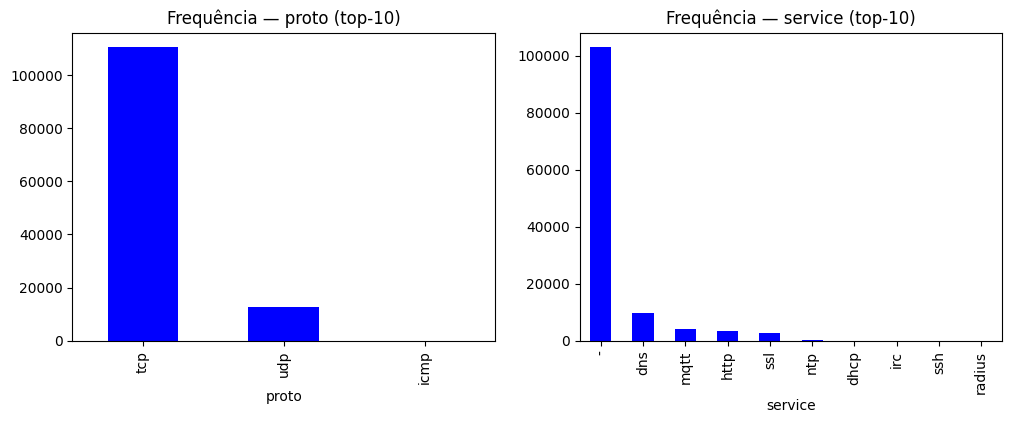

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

for ax, c in zip(axes, ['proto', 'service']):
    df[c].value_counts().head(10).plot(kind='bar', ax=ax, color='blue')
    ax.set_title(f'Frequência — {c} (top-10)')

plt.show()

In [ ]:
categorical_columns = [c for c in df.columns if c not in numeric_columns and c != target_column]

df_cramers = pd.DataFrame({
        "feature": categorical_columns,
        "cramers_v": [cramers_v(df[c], df[target_column]) for c in categorical_columns],
        "nunique": [df[c].nunique() for c in categorical_columns]
    }
).sort_values(by='cramers_v', ascending=False)

display(df_cramers)

   feature  cramers_v
1  service   0.590173
0    proto   0.583314

Quantidade de Valores únicos por coluna categórica:
{'proto': 3, 'service': 10}


### 3.2) Ids

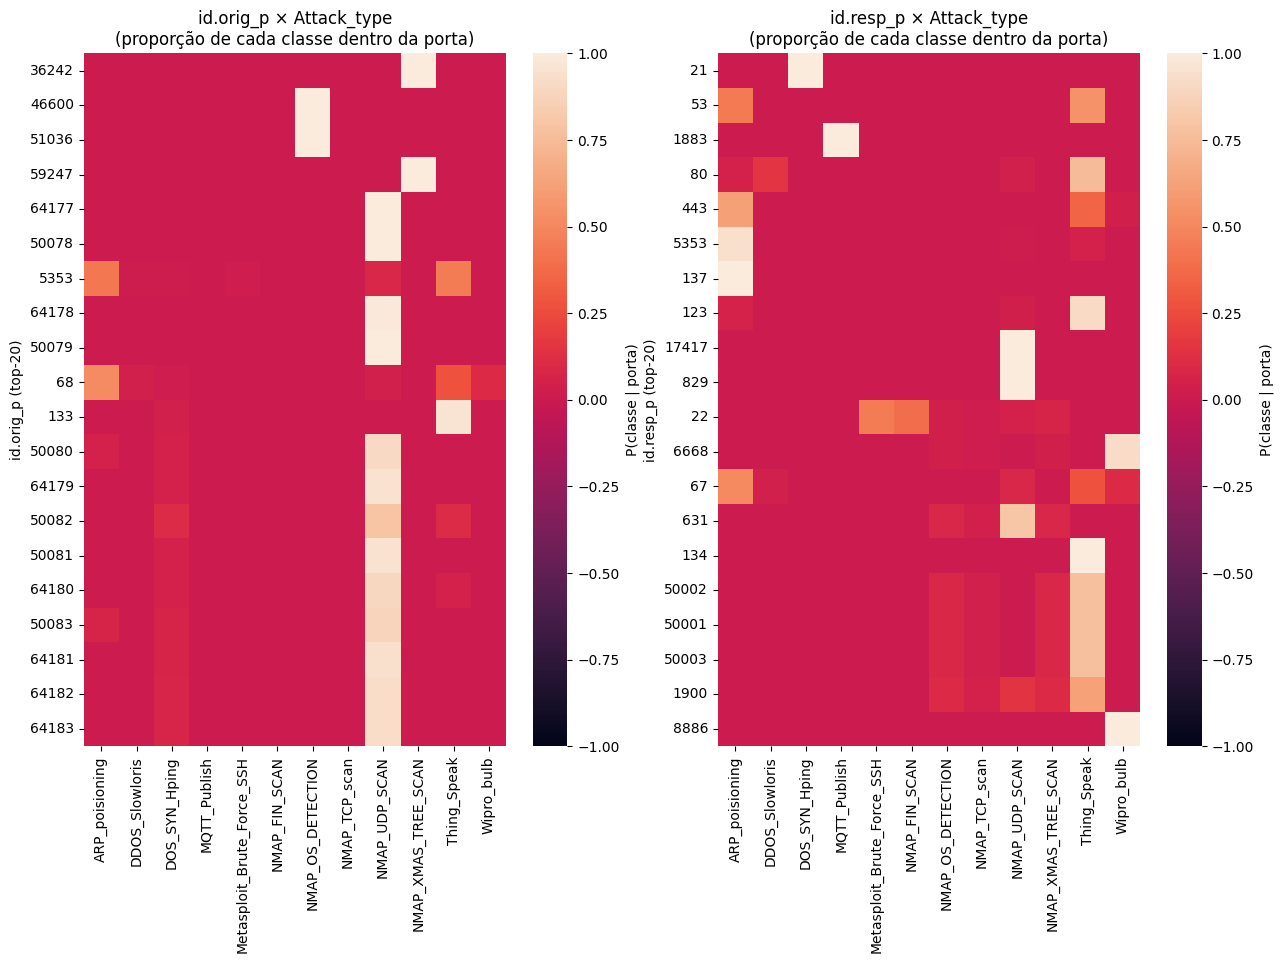

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9))

for ax, col in zip(axes, ['id.orig_p', 'id.resp_p']):
    ct = pd.crosstab(df[col], df[target_column])

    # Recupera as 20 portas mais frequentes
    top = ct.sum(axis=1).sort_values(ascending=False).head(20).index
    ct_pct = ct.loc[top].div(ct.loc[top].sum(axis=1), axis=0)

    # Criação de Heatmap para avaliar o quanto cada coluna de id se correlaciona com o target
    sns.heatmap(ct_pct, ax=ax, vmin=-1, vmax=1, cbar_kws={'label': 'P(classe | porta)'})
    ax.set_title(f'{col} × {target_column}\n(proporção de cada classe dentro da porta)')
    ax.set_xlabel('')
    ax.set_ylabel(f'{col} (top-20)')

plt.show()

In [ ]:
# Testagem com novas features
df_test = df.copy()

df_test['is_same_port'] = (df['id.orig_p'] == df['id.resp_p']).astype("int")
df_test['both_known_well'] = ((df['id.orig_p'] < 1024) & (df['id.resp_p'] < 1024)).astype("int") # server to server
df_test['orig_is_dinamic'] = (df['id.orig_p'] >= 32768).astype("int")
df_test['resp_known_well'] = (df['id.resp_p'] < 1024).astype("int")

results = []
for c in ['id.orig_p', 'id.resp_p', 'is_same_port', 'both_known_well', 'orig_is_dinamic', 'resp_known_well']:
    v = cramers_v(df_test[c], df_test[target_column])
    mi = mutual_info_classif(df_test[[c]], df_test[target_column], discrete_features=True, random_state=42)[0]
    results.append({"coluna": c, "Cramér's V": round(v, 4), "Mutual Info": round(mi, 4)})

print(pd.DataFrame(results).to_markdown(index=False))

c:\Users\rpf97\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)


| coluna          |   Cramér's V |   Mutual Info |
|:----------------|-------------:|--------------:|
| id.orig_p       |       0.1025 |        0.6875 |
| id.resp_p       |       0.6716 |        0.8195 |
| is_same_port    |       0.1106 |        0.0035 |
| both_known_well |       0.0401 |        0.0013 |
| orig_is_dinamic |       0.4464 |        0.1327 |
| resp_known_well |       0.8675 |        0.2594 |


In [ ]:
df = df.drop(columns=['id.orig_p','id.resp_p'])
numeric_columns = df.select_dtypes(include=np.number).columns.to_list()
print(f'Shape: {df.shape}')

Shape: (123117, 81)


### 3.3) Numéricas

In [ ]:
df_encoded = pd.get_dummies(data=df, columns=categorical_columns, drop_first=True, dtype=int)

X_numeric = df_encoded.drop(columns=target_column)
y_encoded = LabelEncoder().fit_transform(df['Attack_type'])

print(f'Features para as Relações Lineares: {X_numeric.shape[1]}')

# Detecta as relações lineares entre as colunas numéricas e a variável target
f_scores, p_value = f_classif(X=X_numeric, y=y_encoded)

# Detecta as relações lineares e não lineares entre as colunas numéricas e a variável target
mi_scores = mutual_info_classif(X_numeric, y_encoded, discrete_features=False, random_state=42)

df_scores = (
    pd.DataFrame({"feature": X_numeric.columns, "f1_anova": f_scores, "p_value": p_value, "mi":  mi_scores})\
    .sort_values('mi', ascending=False).reset_index(drop=True)        
).merge(df_cramers, on='feature', how='left')

display(df_scores.head(15))

,feature,f1_anova,p_value,mi,cramers_v
0,fwd_pkts_payload.avg,23576.777361,0.000000e+00,0.863849,NaN
1,fwd_pkts_payload.max,1989.529229,0.000000e+00,0.859135,NaN
2,fwd_subflow_bytes,463.968378,0.000000e+00,0.852593,NaN
3,flow_pkts_payload.tot,17.266056,9.723187e-35,0.850122,NaN
4,fwd_pkts_payload.tot,158.230934,0.000000e+00,0.847063,NaN
5,flow_pkts_payload.avg,3003.924837,0.000000e+00,0.845817,NaN
6,flow_pkts_payload.max,3470.734791,0.000000e+00,0.844103,NaN
7,fwd_last_window_size,56404.888790,0.000000e+00,0.767228,NaN
8,fwd_init_window_size,20868.408058,0.000000e+00,0.699005,NaN
9,flow_pkts_payload.std,2007.413941,0.000000e+00,0.698997,NaN


### 3.4) Redundância

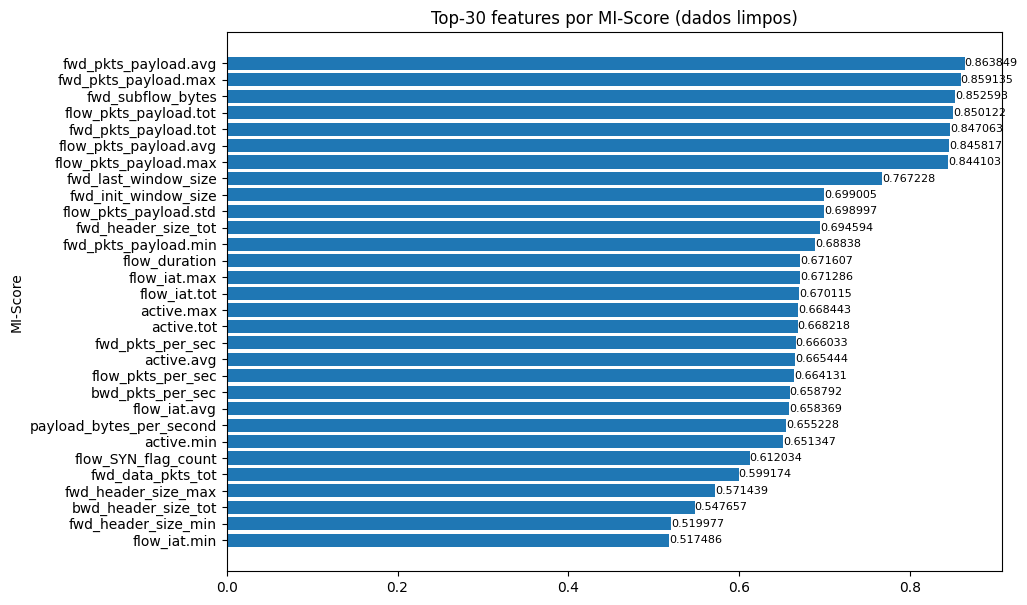

In [ ]:
top_30_mi = df_scores.head(30).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_30_mi['feature'], top_30_mi['mi'])
ax.set_title("Top-30 features por MI-Score (dados limpos)")
ax.set_ylabel("MI-Score")
ax.set_ylabel("Mutual Information")

for container in ax.containers:
    ax.bar_label(container, fontsize=8)

plt.show()

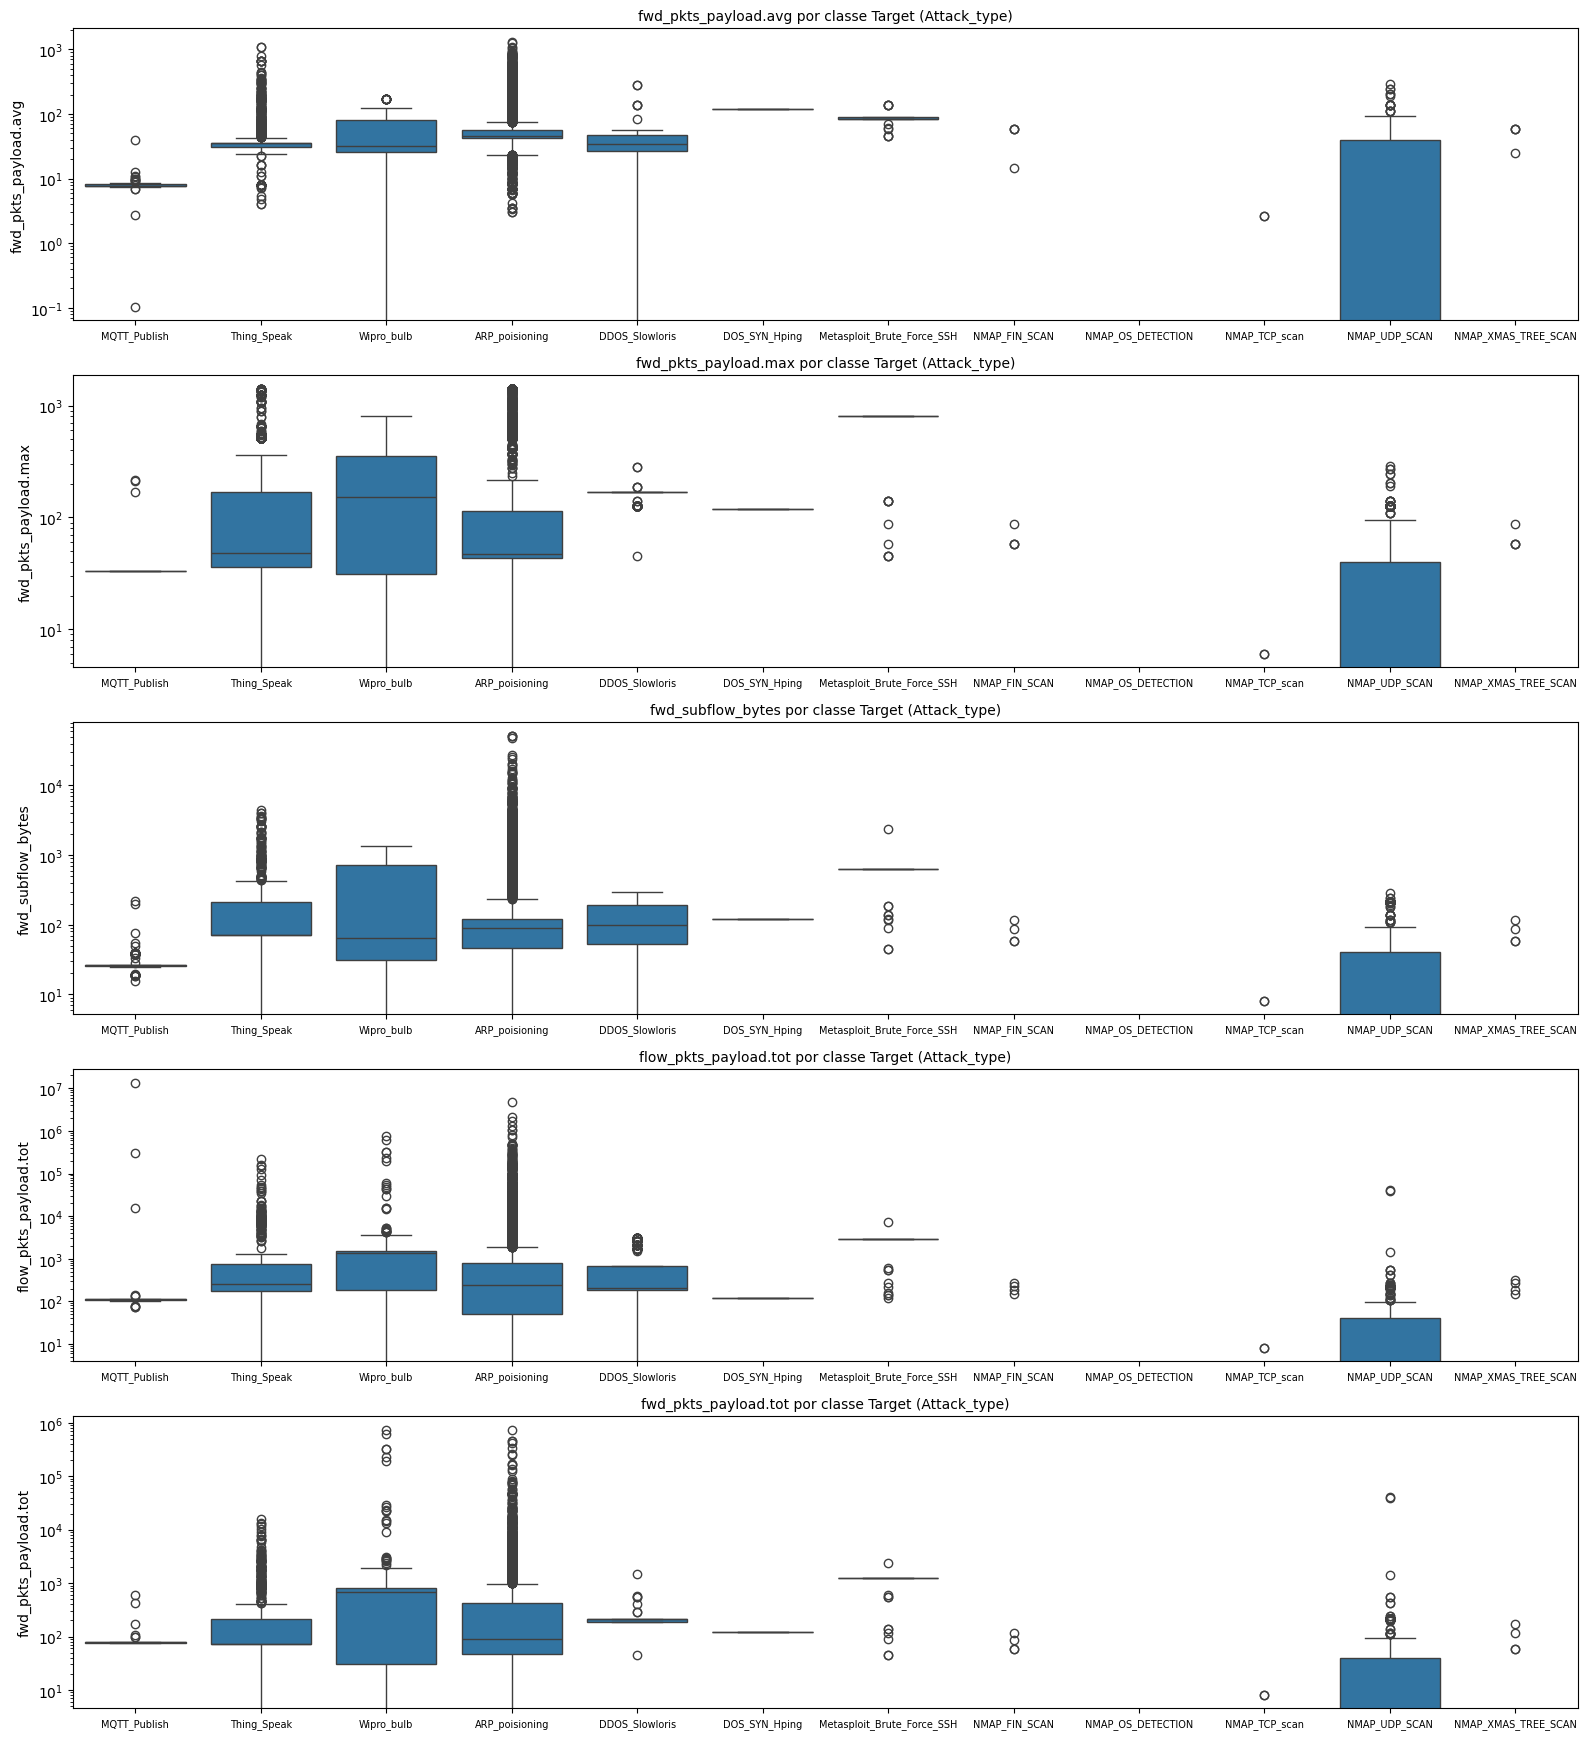

In [ ]:
# Boxplot da classe de top 5 colunas colunas
df_top5 = df_scores.head(5)['feature'].to_list()
df_top5 = [c for c in df_top5 if c in df.columns]

fig, axes = plt.subplots(len(df_top5), 1, figsize=(16, 3.5 * len(df_top5)))

for ax, feature in zip(axes, df_top5):
    sns.boxplot(data=df, x=target_column, y=feature, ax=ax)
    ax.set_yscale('log')
    ax.set_title(f'{feature} por classe Target ({target_column})', fontsize=10)
    ax.tick_params(axis='x', labelsize=7)
    ax.set_xlabel("")

fig.subplots_adjust(hspace=2)
plt.tight_layout()
plt.show()

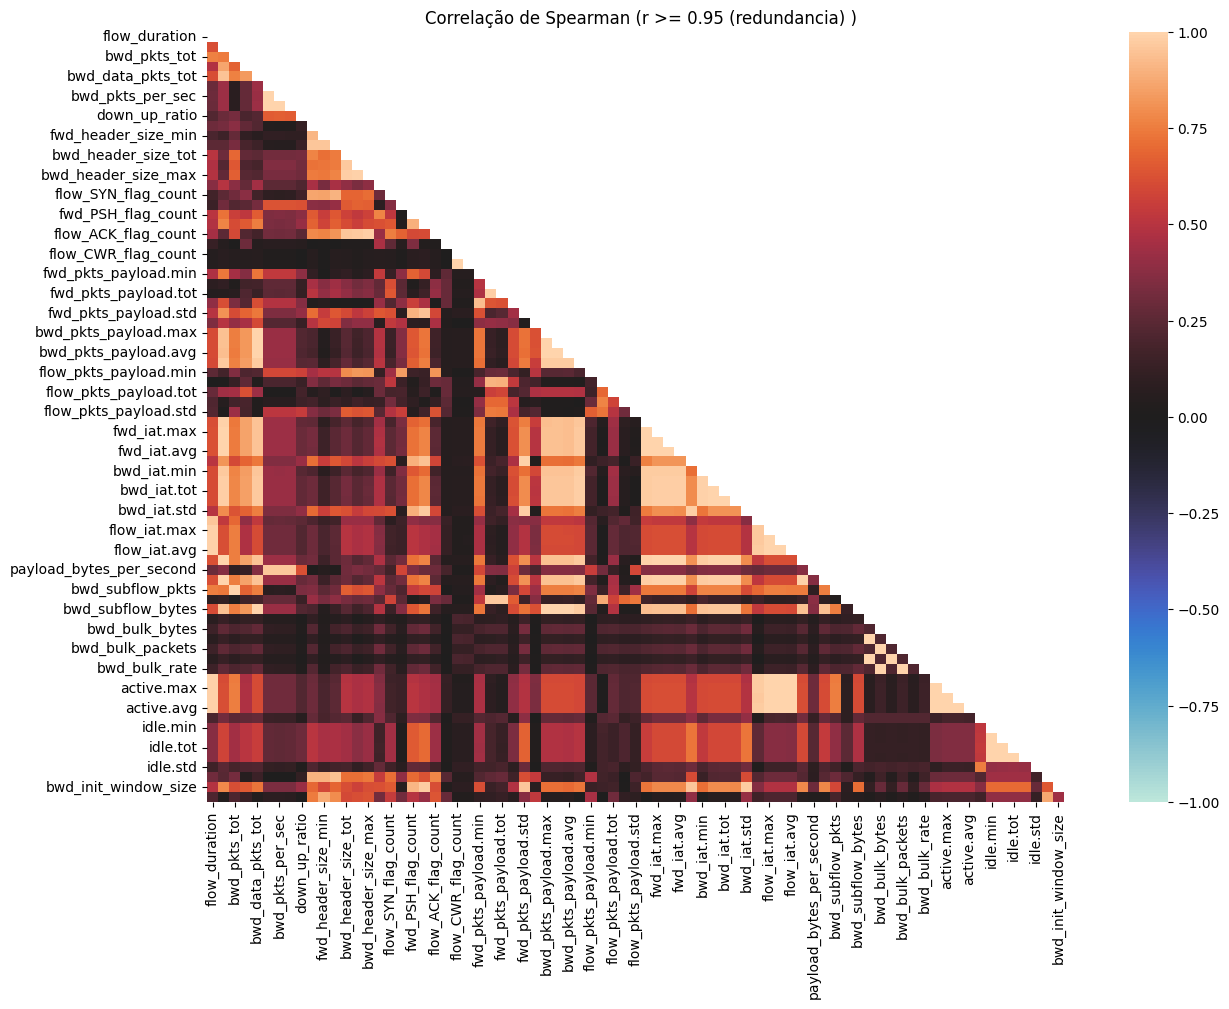

In [ ]:
# Heatmap
full_numeric_correlations = df[numeric_columns].corr(method='spearman').abs()
masked = np.triu(np.ones_like(full_numeric_correlations))

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(
    data=full_numeric_correlations, 
    mask=masked, center=0, vmin=-1, vmax=1
)

plt.title("Correlação de Spearman (r >= 0.95 (redundancia) )")
plt.show()

Ao verificar a alta correlação será agrupado as colunas mais correlacionadas, e então removê-las pelo MI-Score

In [ ]:
def correlated_agroupment(corr_matrix: pd.DataFrame, threshold=0.95):
    """ 
    Agrupa as features conectadas por |p| > threshold usando a matriz completa
    """
    columns = list(corr_matrix.columns)
    condition = corr_matrix > threshold & ~np.eye(len(columns), dtype=bool) # criação de uma matriz bidimensional para identificar  os resultados

    groups, visited = [], set()

    for seed in columns:
        if seed in visited:
            continue

        stack, group = [seed], set()

        while stack:
            node = stack.pop()

            if node in visited:
                continue

            visited.add(node)
            group.add(node)
            stack.extend(c for c in columns if c not in visited and condition.loc[node, c])
        groups.append(group)

    return groups


def choose_columns(group_list: list[dict], importances:dict):
    """ 
    Para cada grupo será escolhido a feature com mais importância
    """
    keep_columns, remove_columns = [], []
    
    for g in group_list:
        if len(g) == 1:
            keep_columns.append(next(iter(g)))
            continue
        
        best = max(g, key=lambda f: importances.get(f))
        keep_columns.append(best)
        remove_columns.extend(g - {best})

    return keep_columns, remove_columns

In [ ]:
groups = correlated_agroupment(corr_matrix=full_numeric_correlations)
importances = dict(zip(df_scores['feature'], df_scores['mi']))
print(f'Total de grupos correlacionados: {len(groups)}\n')

keep_columns, remove_columns = choose_columns(group_list=groups, importances=importances)

print(f'Total de colunas a manter: {len(keep_columns)}')
print(f'Total de colunas a remover: {len(remove_columns)}')
print(pd.DataFrame(remove_columns, columns=['Colunas']).to_markdown(index=False))

Total de colunas redundantes: 44

Total de grupos correlacionados: 34

Total de colunas a manter: 34
Total de colunas a remover: 44
| Colunas                  |
|:-------------------------|
| bwd_subflow_pkts         |
| fwd_header_size_max      |
| flow_ECE_flag_count      |
| bwd_init_window_size     |
| bwd_PSH_flag_count       |
| fwd_pkts_payload.tot     |
| fwd_subflow_bytes        |
| fwd_bulk_packets         |
| fwd_bulk_rate            |
| bwd_bulk_packets         |
| bwd_bulk_rate            |
| payload_bytes_per_second |
| flow_pkts_per_sec        |
| bwd_pkts_per_sec         |
| bwd_header_size_max      |
| bwd_header_size_min      |
| flow_ACK_flag_count      |
| fwd_iat.std              |
| idle.avg                 |
| idle.tot                 |
| idle.min                 |
| flow_iat.min             |
| active.max               |
| flow_iat.tot             |
| active.avg               |
| active.tot               |
| flow_iat.avg             |
| flow_iat.max             

In [ ]:
df_reduzed = df.drop(columns=remove_columns) #.drop_duplicates().reset_index(drop=True)
print(f"Antes: {df.shape} | Depois: {df_reduzed.shape}")
df_encoded = pd.get_dummies(data=df_reduzed, columns=categorical_columns, drop_first=True, dtype=int)
print(f'Encoded Shape: {df_encoded.shape}')

Antes: (123117, 81) | Depois: (123117, 37)
Encoded Shape: (123117, 46)


### 4) Redução de Dimensionalidade

#### 4.1) PCA

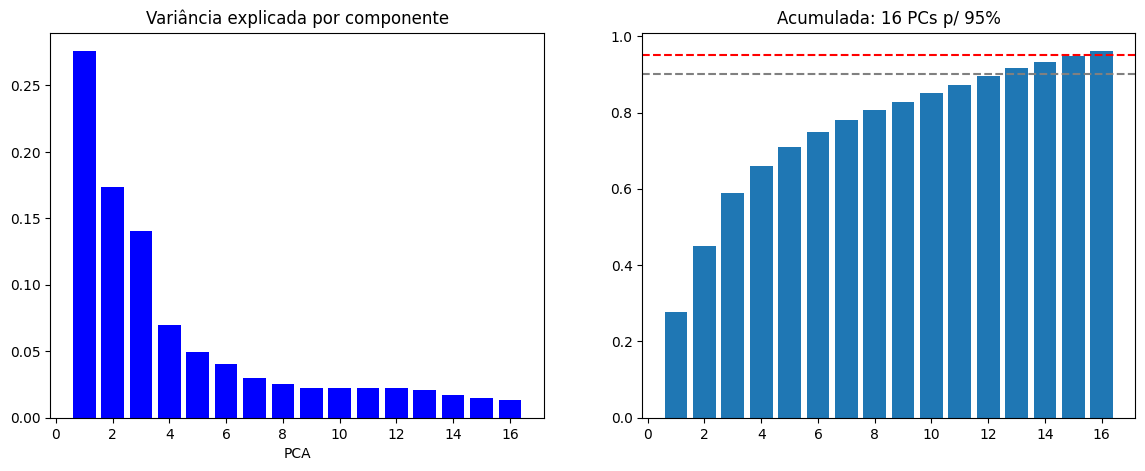

In [ ]:
feature_columns = [c for c in df_encoded.columns if c != target_column]

# Utilização de colunas numéricas sem o target
X_pca = np.log1p(df_encoded[feature_columns].clip(lower=0)) # log1p exige valores >=0

# Padronização de Dados 
X_scaled = StandardScaler().fit_transform(X_pca)

# PCA
pca = PCA(random_state=42, n_components=0.95).fit(X_scaled)
variance_ratio = pca.explained_variance_ratio_
cum_sum = np.cumsum(variance_ratio)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, len(variance_ratio)+1), variance_ratio, color='blue')
axes[0].set_title("Variância explicada por componente")
axes[0].set_xlabel("PCA")

axes[1].bar(range(1, len(cum_sum)+1), cum_sum)
axes[1].axhline(0.9, ls='--', c='gray'); 
axes[1].axhline(0.95, ls='--', c='red')
axes[1].set_title(f'Acumulada: {len(variance_ratio)} PCs p/ 95%')

plt.show()

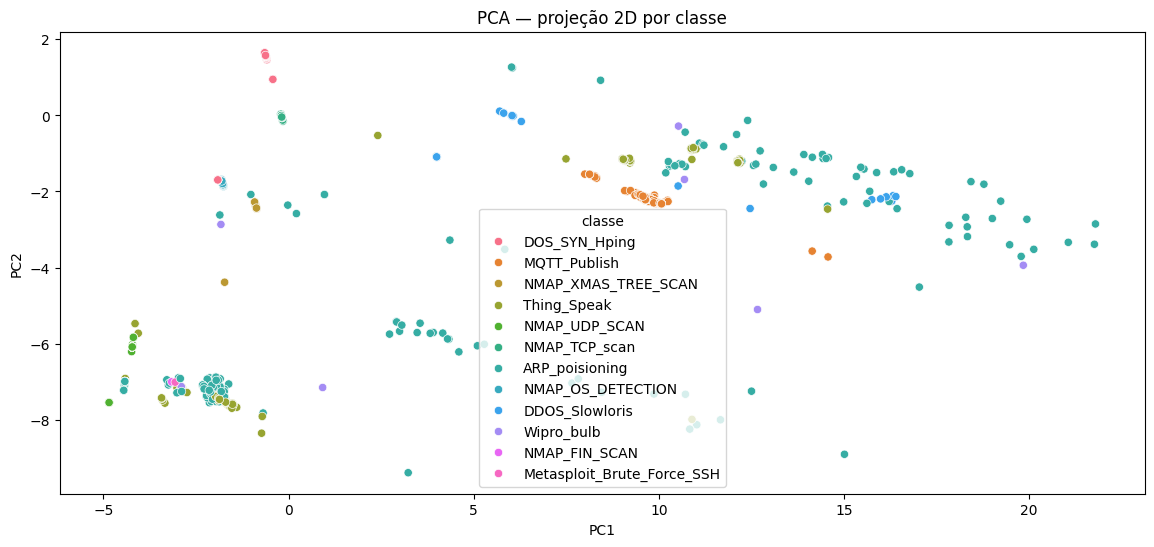

In [ ]:
# Scatter PC1 x PC2
pca2 = PCA(random_state=42, n_components=2).fit_transform(X_scaled)
df_pca = pd.DataFrame(pca2, columns=["PC1", "PC2"])
df_pca['classe'] = df[target_column].values

plt.figure(figsize=(14, 6))
sns.scatterplot(data=df_pca.sample(5000, random_state=42), x='PC1', y='PC2', hue='classe' ) # plotar um gráfico de uma amostra de 5000
plt.title('PCA — projeção 2D por classe')
plt.show()

#### 4.2) T-SNE

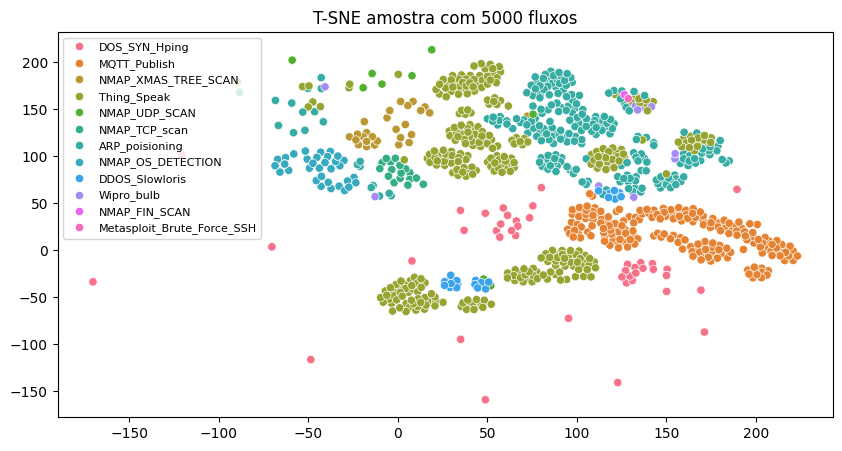

In [ ]:
idx = np.random.RandomState(42).choice(len(X_scaled), 5000, replace=False) # Retorno dos índices de amostras aleatórias
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42, learning_rate='auto', init='pca').fit_transform(X_scaled[idx]) # calculo do T-SNE

plt.figure(figsize=(10, 5))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=df_encoded[target_column].iloc[idx])
plt.title("T-SNE amostra com 5000 fluxos")
plt.legend(loc='upper left',  fontsize=8)
plt.show()

In [ ]:
# DEPOIS de remover ids e dedup
dist_final = df[target_column].value_counts()
dist_pct = (dist_final / len(df) * 100).round(2)

print(f"Total: {len(df):,} fluxos")
print(pd.DataFrame({'count': dist_final, 'pct': dist_pct}))

Total: 123,117 fluxos
                            count    pct
Attack_type                             
DOS_SYN_Hping               94659  76.89
Thing_Speak                  8108   6.59
ARP_poisioning               7750   6.29
MQTT_Publish                 4146   3.37
NMAP_UDP_SCAN                2590   2.10
NMAP_XMAS_TREE_SCAN          2010   1.63
NMAP_OS_DETECTION            2000   1.62
NMAP_TCP_scan                1002   0.81
DDOS_Slowloris                534   0.43
Wipro_bulb                    253   0.21
Metasploit_Brute_Force_SSH     37   0.03
NMAP_FIN_SCAN                  28   0.02


# 5) Conclusões

### Sobre os Dados
- (123.117 linhas x 84 colunas) (81 numéricas, 3 categóricas)

- Não apresenta valores nulos (Não precisa adaptar)

- Não apresenta valores negativos

- Apresenta 5195 valores duplicados (4.22% do total) -> deve remover antes do split

- Foram removidas uma coluna constante 'bwd_URG_flag_count' (número de flags urg em pacotes de volta) 
  e duas colunas colunas de Id de porta de entrada e saída para poderem evitar vazamento de dados e overfitting

- Foi optado em não remover as duplicadas, por causa da má distribuição do target, que apresenta classes
  com poucos exemplos, o que prejudicaria no poder preditivo

- o Outlier é apresentado em até 31% em algumas colunas (sendo elas 'flow_pkts_payload.avg' e 'bwd_header_size_tot')


### Sobre A coluna target (Attack_Type)

- O target é fortemente desbalanceado, são divididos em 12 categorias com grave desbalanceamento
  * DOS_SYN_Hping (aproximandamente 76.5%)
  * Enquanto as outras classes vao de 6.5% para baixo
- **Conclusão**: a acurácia é enganosa (ocorre quando um modelo assume que a classe majoritária acerta)


### Sobre os Outliers

* Existem muitos outliers porque os dados apresentados são assimétricos, removê-los não melhoraria no modelo porque os outliers podem indicar o próprio ataque


### Sobre os ids (id.resp_p, id.orig_p)

Diante de uma requisição de rede, existem duas portas: uma de origem (realiza a chamada e deveria ser aleatória) e uma de resposta (que recebe e mapeia o serviço).

Durante a análise, teve um palpite de que manter essas colunas geraria vazamento de dados (data leakage), fazendo com que o modelo "decorasse" a resposta em vez de aprender o comportamento do tráfego. Para testar, foi avaliado as duas colunas e algumas features ligadas a elas:

* **id.resp_p**: apresentou Cramér's V de 0.67 e MI de 0.83, confirmando uma associação alta

* **id.orig_p**:  Apesar de ter uma independência com o target em  Cramér's V (0), o MI foi de 0.7, indicando que o modelo também consegue decorar ataques olhando a porta de origem

* **Teste de Par**: Foram criadas variáveis de teste para avaliar a relação entre as duas portas. Foi descoberto que a coluna 'resp_known_well' tem o valor de Cramér's V de 0.87 (forte associação) e  'orig_is_dinamic' tem o valor de Cramér's V de 0.45 (ataques diferem do tipo de porta de origem que utilizam). Porém as colunas 'is_same_port' e 'both_known_well' ficam com MI igual a 0 (sem conexões locais entre os servidores da internet)

**Conclusão**: Ambas as colunas (id.orig_p e id.resp_p) devem ser removidas por fornecerem "respostas prontas" e atalhos que prejudicam o aprendizado. Caso um ataque real ou novo pudesse vir de uma porta desconhecida, ou atacar um serviço em uma porta não padronizada, o modelo iria falhar por ter decorado as portas do teste



### Sobre As correlações

- Apresentaram colunas que geram uma alta redundância em si, tornando o modelo ineficaz, Portanto ao reavaliar as colunas por meio das medidas de correlção e então agrupá-las para verificar qual é a melhor através do MI-Score, poderão ser removidas 1 coluna